# Chapitre 8 - Exercices 8.5 à 8.7

* **8.5** - Généraliser les fonctions de perte de la figure 10.4 à plus de deux classes.
* **8.6** - Données de densité osseuse : spline de lissage, bandes fréquentistes,
  bayésiennes et bootstrap.
* **8.7** - L'algorithme EM vu comme un algorithme MM (minoration-maximisation).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## Exercice 8.5 : Fonctions de perte pour plus de deux classes

**Énoncé.** Proposer des généralisations à plus de deux classes de chacune des fonctions
de perte de la figure 10.4 du livre, et concevoir un graphique adapté pour les comparer.

### Rappel : la figure 10.4 (cas à deux classes)

Avec $y \in \{-1, +1\}$, une fonction de score $f(x) \in \mathbb R$ et la règle
$\hat G(x) = \mathrm{signe}(f(x))$, toutes les pertes s'écrivent en fonction de la
**marge** $yf$ :

| perte | formule | rôle |
|---|---|---|
| erreur de classement | $\mathbb 1\{yf < 0\}$ | critère visé |
| exponentielle | $e^{-yf}$ | AdaBoost (chap. 10) |
| déviance binomiale | $\log(1 + e^{-2yf})$ | régression logistique |
| erreur quadratique | $(y - f)^2 = (1 - yf)^2$ | régression sur l'indicatrice |
| « support vector » | $(1 - yf)_+$ | SVM (chap. 12) |

Dans la figure 10.4, chaque perte est normalisée pour valoir 1 en $yf = 0$ (la déviance est
divisée par $\log 2$).

### Codage à $K$ classes

On utilise un **vecteur de scores** $f = (f_1, \dots, f_K)$ soumis à la contrainte
$\sum_k f_k = 0$ (sans elle, ajouter une constante à tous les $f_k$ ne changerait pas le
classement) et la règle $\hat G = \arg\max_k f_k$. La classe observée $k$ est codée par le
vecteur symétrique (codage de Zhu et al., repris pour AdaBoost multiclasse)

$$y_j = 1 \text{ si } j = k, \qquad y_j = -\tfrac{1}{K-1} \text{ sinon},
\qquad\text{de sorte que } \textstyle\sum_j y_j = 0.$$

Pour $K = 2$, $y = (\pm 1, \mp 1)$ et $f = (f_1, -f_1)$ : on retrouve le cadre à deux
classes avec $f = f_1$.

### Les généralisations proposées

| perte | généralisation à $K$ classes (classe observée $k$) | valeur en $f = 0$ |
|---|---|---|
| erreur de classement | $\mathbb 1\{\arg\max_j f_j \ne k\}$ | - |
| exponentielle | $\exp\big(-\tfrac1K\,y^Tf\big)$ | 1 |
| déviance multinomiale | $-\log p_k(f)$, $p_k = e^{f_k}/\sum_j e^{f_j}$ (éq. (4.17), (10.22)) | $\log K$ |
| erreur quadratique | $\sum_j (y_j - f_j)^2$ | $K/(K-1)$ |
| « support vector » (Lee, Lin, Wahba) | $\sum_{j\ne k}\big(f_j + \tfrac{1}{K-1}\big)_+$ | 1 |
| « support vector » (Crammer, Singer) | $\big(1 - [f_k - \max_{j\ne k}f_j]\big)_+$ | 1 |

Pour comparer, on normalise comme dans la figure 10.4 pour que chaque perte vaille 1 en
$f = 0$ (déviance divisée par $\log K$, erreur quadratique multipliée par $(K-1)/K$).

### Vérification : retour au cas $K = 2$

Avec $K = 2$, $y = (1, -1)$ et $f = (f_1, -f_1)$ :

* exponentielle : $y^Tf/2 = (f_1 + f_1)/2 = f_1$, donc $e^{-f_1}$ ✓ ;
* déviance : $p_1 = e^{f_1}/(e^{f_1} + e^{-f_1}) = 1/(1 + e^{-2f_1})$, donc
  $-\log p_1 = \log(1 + e^{-2f_1})$ ✓ ;
* quadratique : $(1 - f_1)^2 + (-1 + f_1)^2 = 2(1 - f_1)^2$, normalisée : $(1 - f_1)^2$ ✓ ;
* Lee-Lin-Wahba : $(f_2 + 1)_+ = (1 - f_1)_+$ ✓ ;
* Crammer-Singer : $(1 - 2f_1)_+$ : c'est la perte SVM à un changement d'échelle de $f$ près.

In [2]:
def coding(k, K):
    y = np.full(K, -1.0 / (K - 1)); y[k] = 1.0
    return y

def losses(f, k):
    """Pertes multiclasses normalisées (valent 1 en f = 0). f : (n, K), classe observée k."""
    K = f.shape[1]
    y = coding(k, K)
    others = np.delete(np.arange(K), k)
    logp = f[:, k] - np.log(np.exp(f).sum(1))
    margin = f[:, k] - f[:, others].max(1)
    return {
        "erreur de classement": (f.argmax(1) != k).astype(float),
        "exponentielle": np.exp(-f @ y / K),
        "déviance multinomiale": -logp / np.log(K),
        "erreur quadratique": ((y - f) ** 2).sum(1) * (K - 1) / K,
        "SVM (Lee-Lin-Wahba)": np.clip(f[:, others] + 1 / (K - 1), 0, None).sum(1),
        "SVM (Crammer-Singer)": np.clip(1 - margin, 0, None),
    }

t = np.linspace(-2, 2, 9)
f2 = np.column_stack([t, -t])
L2 = losses(f2, 0)
print("K = 2, vérification des formules à deux classes :")
print("  exponentielle :", np.allclose(L2["exponentielle"], np.exp(-t)))
print("  déviance      :", np.allclose(L2["déviance multinomiale"], np.log1p(np.exp(-2 * t)) / np.log(2)))
print("  quadratique   :", np.allclose(L2["erreur quadratique"], (1 - t) ** 2))
print("  SVM (LLW)     :", np.allclose(L2["SVM (Lee-Lin-Wahba)"], np.clip(1 - t, 0, None)))

K = 2, vérification des formules à deux classes :
  exponentielle : True
  déviance      : True
  quadratique   : True
  SVM (LLW)     : True


### Premier graphique : une coupe à une dimension

Le long de la direction du codage, $f = t\,y$ (on augmente le score de la bonne classe et
l'on diminue uniformément les autres), $t$ joue le rôle de la marge $yf$ : on obtient
l'analogue direct de la figure 10.4. Un calcul simple donne $e^{-t/(K-1)}$ pour
l'exponentielle, $(1 - t)^2$ pour la quadratique et $(1 - t)_+$ pour Lee-Lin-Wahba.

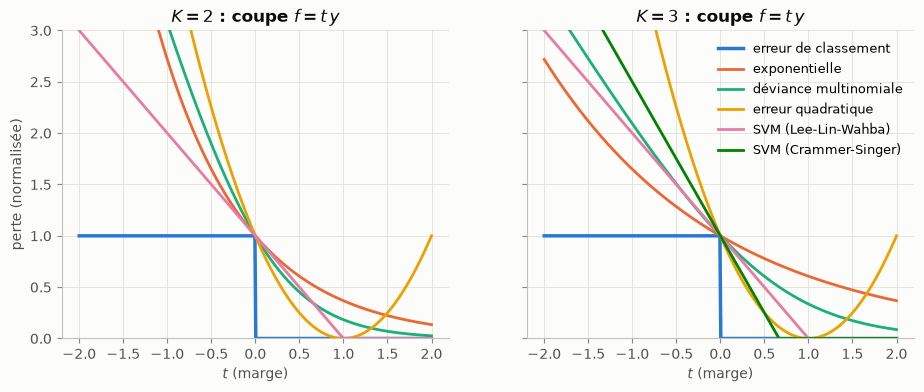

In [3]:
tt = np.linspace(-2, 2, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, K in zip(ax, [2, 3]):
    Lk = losses(tt[:, None] * coding(0, K)[None, :], 0)
    for c, (name, v) in zip(COLORS, Lk.items()):
        if K == 2 and name == "SVM (Crammer-Singer)":
            continue
        a.plot(tt, v, color=c, label=name, lw=2 if name != "erreur de classement" else 2.5)
    a.set(title="$K = %d$ : coupe $f = t\\,y$" % K, xlabel="$t$ (marge)", ylim=(0, 3))
ax[0].set_ylabel("perte (normalisée)")
ax[1].legend(loc="upper right")
plt.show()

Cette coupe ne montre qu'une direction : avec $K \ge 3$, une perte dépend de **tout** le
vecteur $f$, en particulier de la façon dont se répartissent les scores des mauvaises
classes.

### Second graphique : le plan $\sum_k f_k = 0$ pour $K = 3$

Pour $K = 3$, les scores admissibles forment un plan, que l'on paramètre par une base
orthonormée $(e_1, e_2)$ : $f = u\,e_1 + v\,e_2$. On choisit $e_1$ colinéaire au codage
de la classe 1 (vraie classe). Les traits gris délimitent les régions où chaque classe
est prédite ; la région de bonne classification est à droite.

In [4]:
K = 3
e1 = coding(0, K) / np.linalg.norm(coding(0, K))
e2 = np.array([0.0, 1.0, -1.0]) / np.sqrt(2)
uu, vv = np.meshgrid(np.linspace(-2.5, 2.5, 241), np.linspace(-2.5, 2.5, 241))
Fp = uu.ravel()[:, None] * e1 + vv.ravel()[:, None] * e2
L3 = losses(Fp, 0)

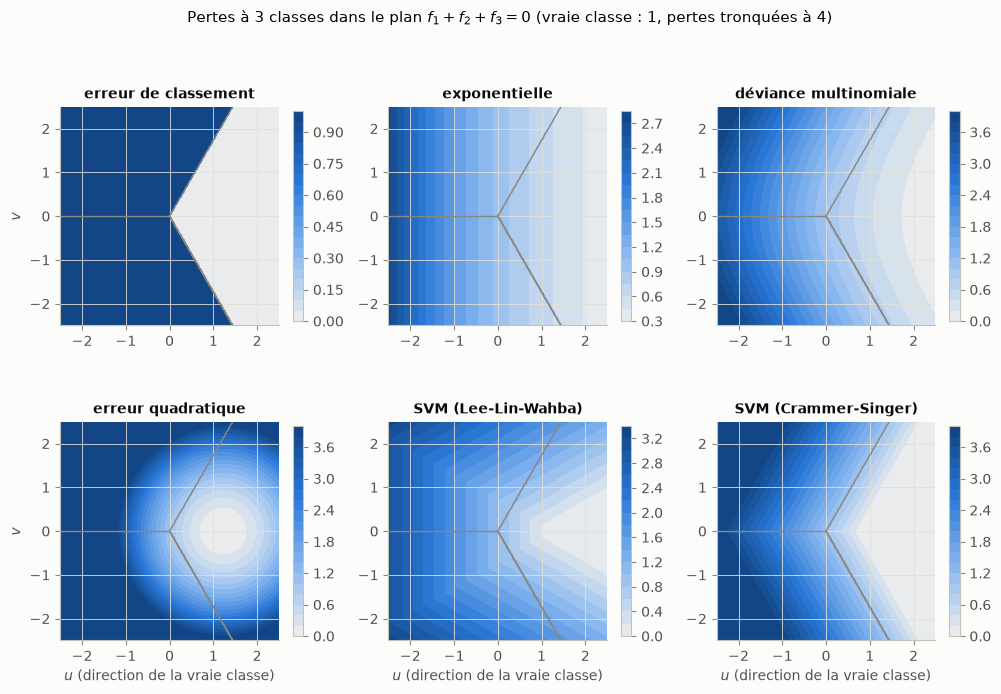

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for a, (name, v) in zip(axes.ravel(), L3.items()):
    im = a.contourf(uu, vv, np.minimum(v, 4).reshape(uu.shape), levels=20, cmap=SEQ)
    a.contour(uu, vv, Fp.argmax(1).reshape(uu.shape), levels=[0.5, 1.5], colors=GRAY,
              linewidths=1)
    a.set_title(name, fontsize=10)
    a.set_aspect("equal")
    fig.colorbar(im, ax=a, shrink=0.8)
for a in axes[1]:
    a.set_xlabel("$u$ (direction de la vraie classe)")
for a in axes[:, 0]:
    a.set_ylabel("$v$")
fig.suptitle("Pertes à 3 classes dans le plan $f_1+f_2+f_3=0$ (vraie classe : 1, pertes tronquées à 4)",
             fontsize=11)
plt.show()

On lit sur ces cartes :

* l'exponentielle et la déviance décroissent dans toute la région de bonne classification
  (elles continuent à « pousser » la marge) ; l'exponentielle croît exponentiellement
  dans la mauvaise région, la déviance seulement linéairement (plus robuste) ;
* la perte quadratique pénalise aussi les scores **trop** grands (bol centré sur le
  codage) ;
* les deux pertes SVM sont nulles au-delà d'une marge, mais avec des géométries
  différentes : Lee-Lin-Wahba pénalise chaque mauvaise classe séparément,
  Crammer-Singer seulement la plus menaçante.

### Un critère de comparaison : la cohérence de Fisher

Une perte est **Fisher-cohérente** si le minimiseur de la perte espérée
$E[L(Y, f)\mid x] = \sum_k p_k L(k, f)$ (avec $p_k = \Pr(Y = k\mid x)$) prédit la classe de
Bayes $\arg\max_k p_k$. Calculons ces minimiseurs numériquement pour deux vecteurs $p$
(dans le plan, à l'aide de Nelder-Mead).

In [6]:
def expected_loss(uv, p, name):
    f = (uv[0] * e1 + uv[1] * e2)[None, :]
    return sum(p[k] * losses(f, k)[name][0] for k in range(K))

for p in [np.array([0.6, 0.25, 0.15]), np.array([0.4, 0.35, 0.25])]:
    print("p =", p)
    for name in list(L3)[1:]:
        best = min((optimize.minimize(expected_loss, x0, args=(p, name), method="Nelder-Mead",
                                      options={"xatol": 1e-7, "fatol": 1e-10, "maxiter": 4000})
                    for x0 in rng.randn(6, 2)), key=lambda r: r.fun)
        f_opt = best.x[0] * e1 + best.x[1] * e2
        print("   %-24s f* = %s" % (name, np.round(f_opt, 3)))

p = [0.6  0.25 0.15]
   exponentielle            f* = [ 1.508 -0.243 -1.265]
   déviance multinomiale    f* = [ 0.754 -0.122 -0.632]
   erreur quadratique       f* = [ 0.4   -0.125 -0.275]
   SVM (Lee-Lin-Wahba)      f* = [ 1.  -0.5 -0.5]


   SVM (Crammer-Singer)     f* = [ 0.667 -0.333 -0.333]
p = [0.4  0.35 0.25]
   exponentielle            f* = [ 0.402  0.135 -0.538]
   déviance multinomiale    f* = [ 0.201  0.068 -0.269]
   erreur quadratique       f* = [ 0.1    0.025 -0.125]


   SVM (Lee-Lin-Wahba)      f* = [ 1.  -0.5 -0.5]
   SVM (Crammer-Singer)     f* = [ 0.  0. -0.]
